## Access 5D AIS DATA

Description: "The dataset provides classifications of supraglacial hydrology, distinguishing open meltwater features, including lakes, channels, and water-filled crevasses, from non-open meltwater features such as saturated firn and slush. By resolving Antarctic surface hydrology at unprecedented spatial and temporal scales and enabling on-demand delineation of meltwater features through a publicly available application, this work supports the assessment of processes relevant to ice-shelf stability and provides constraints for climate and ice-sheet modelling. This capability is increasingly important for understanding the role of surface meltwater in Antarctic ice-shelf systems under future warming.",

Original Data Source: https://opensciencedata.esa.int/products/5dais/collection

Reference: https://opensciencedata.esa.int/products/5dais/collection

OSC entry: https://opensciencedata.esa.int/products/5dais/collection

License: CC-BY-4.0

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import fsspec
from pystac_client import Client
from IPython.display import display

In [3]:
data_url = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/5dais/5DAIS_ALL_polygons.parquet'

gdf = gpd.read_parquet(data_url, filesystem=fsspec.filesystem("https"))
gdf

,geometry,source_file,source_path,raster_width,raster_height,raster_transform,raster_crs,raster_dtype,raster_nodata,raster_fill_value,class_id,class_label,has_observation
0,"POLYGON ((-91.58414 -72.77611, -91.58414 -72.7...",SGH_Abbot_20162017_Dec,AIS_SGH_Rasters_100m-Abbot/SGH_Abbot_20162017_...,16868,2041,"[0.0008983152841195215, 0.0, -103.494005568125...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,True
1,"POLYGON ((-91.58055 -72.77701, -91.58055 -72.7...",SGH_Abbot_20162017_Dec,AIS_SGH_Rasters_100m-Abbot/SGH_Abbot_20162017_...,16868,2041,"[0.0008983152841195215, 0.0, -103.494005568125...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,True
2,"POLYGON ((-91.57336 -72.77791, -91.57336 -72.7...",SGH_Abbot_20162017_Dec,AIS_SGH_Rasters_100m-Abbot/SGH_Abbot_20162017_...,16868,2041,"[0.0008983152841195215, 0.0, -103.494005568125...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,True
3,"POLYGON ((-95.79634 -72.94769, -95.79634 -72.9...",SGH_Abbot_20162017_Dec,AIS_SGH_Rasters_100m-Abbot/SGH_Abbot_20162017_...,16868,2041,"[0.0008983152841195215, 0.0, -103.494005568125...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,True
4,"POLYGON ((-95.79994 -72.9423, -95.79994 -72.94...",SGH_Abbot_20162017_Dec,AIS_SGH_Rasters_100m-Abbot/SGH_Abbot_20162017_...,16868,2041,"[0.0008983152841195215, 0.0, -103.494005568125...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3034587,None,SGH_Zubchatyy_20232024_Jan,AIS_SGH_Rasters_100m-Zubchatyy/SGH_Zubchatyy_2...,1449,599,"[0.0008983152841195215, 0.0, 48.33834543847146...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,False
3034588,None,SGH_Zubchatyy_20242025_Feb,AIS_SGH_Rasters_100m-Zubchatyy/SGH_Zubchatyy_2...,1449,599,"[0.0008983152841195215, 0.0, 48.33834543847146...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,1,class_1,False
3034589,None,SGH_Zubchatyy_20242025_Feb,AIS_SGH_Rasters_100m-Zubchatyy/SGH_Zubchatyy_2...,1449,599,"[0.0008983152841195215, 0.0, 48.33834543847146...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,2,class_2,False
3034590,None,SGH_Zubchatyy_20242025_Jan,AIS_SGH_Rasters_100m-Zubchatyy/SGH_Zubchatyy_2...,1449,599,"[0.0008983152841195215, 0.0, 48.33834543847146...","GEOGCS[""WGS 84"",DATUM[""WGS_1984"",SPHEROID[""WGS...",int32,None,0,1,class_1,False


## Data structure

 - Each row is a spatially contiguous region of the same class - a  lake, or slush
 - The source file column describes encodes the region, Antarctic melt season and month. For example, SGH_Abbot_20162017_Dec identifies supraglacial hydrology for the Abbot region in December 2016, within the 2016–2017 melt season.
 - In the supplied naming scheme, class_0 represents background, class_1 represents open meltwater, and class_2 represents slush.
 - An empty geometry means that there are no deliniated observation for that period and region.

In [4]:
antarctic_crs = ccrs.SouthPolarStereo(
    central_longitude=0,
    true_scale_latitude=-71,
)

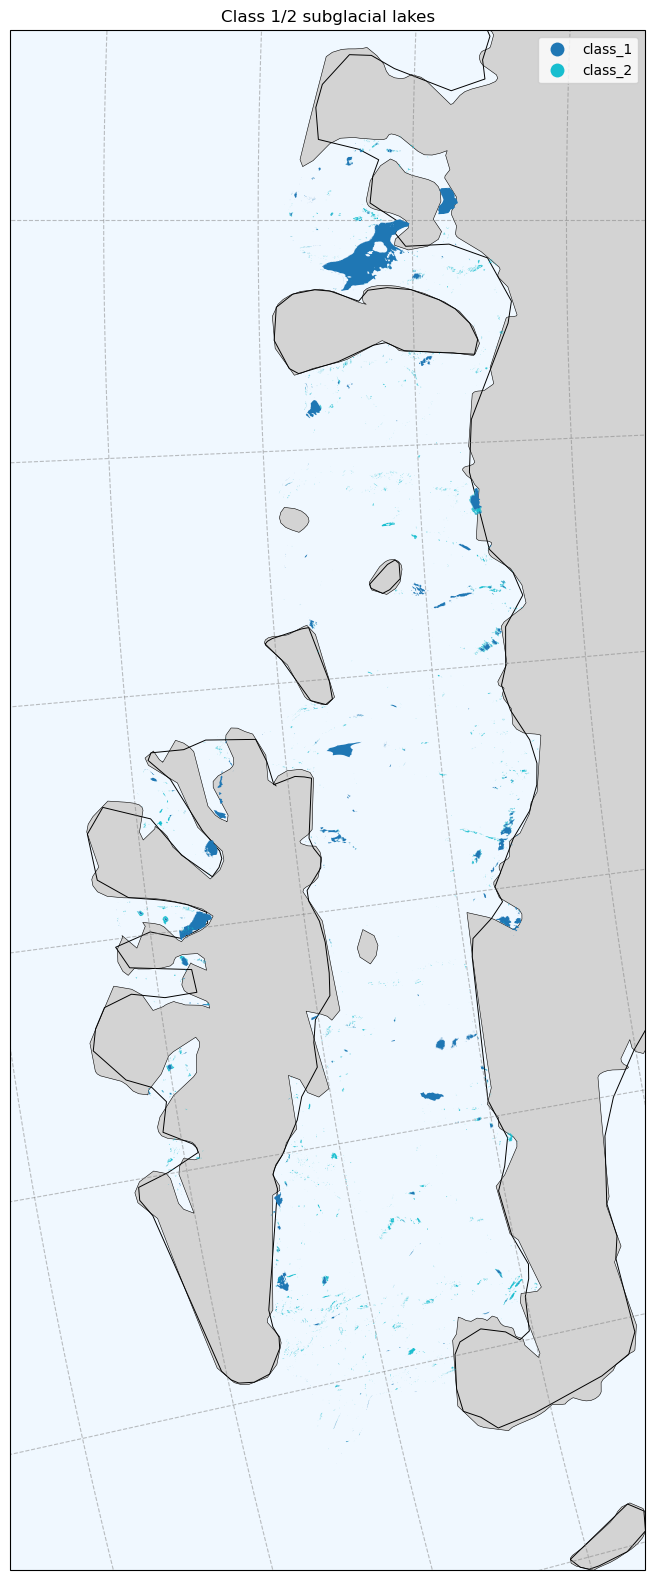

In [5]:
gdf_3031 = gdf.head(10_000).to_crs(epsg=3031)

fig, ax = plt.subplots(
    figsize=(20, 20),
    subplot_kw={"projection": antarctic_crs},
)

ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.add_feature(cfeature.LAND, facecolor="lightgray", edgecolor="black", linewidth=0.4, zorder=1)
ax.coastlines(resolution="50m", color="black", linewidth=0.7, zorder=2)
ax.gridlines(draw_labels=False, color="gray", alpha=0.5, linestyle="--")

gdf_3031.plot(column="class_label", legend=True, ax=ax, zorder=3)

minx, miny, maxx, maxy = gdf_3031.total_bounds
pad = max(maxx - minx, maxy - miny) * 0.08
ax.set_extent([minx - pad, maxx + pad, miny - pad, maxy + pad], crs=antarctic_crs)

ax.set_title("Class 1/2 subglacial lakes")
plt.show()

## Generate a 100m grid from the data

The raster columns give enough information to recreate the original raster grid, burning the class values into the raster.


In [6]:
from affine import Affine
from rasterio.features import rasterize

group = gdf[gdf['source_path'] == 'AIS_SGH_Rasters_100m-Abbot/SGH_Abbot_20162017_Dec.tif']

row = gdf.iloc[0]

data = rasterize(
    (
        (geom, int(class_id))
        for geom, class_id in zip(group.geometry, group["class_id"])
    ),
    out_shape=(int(row["raster_height"]), int(row["raster_width"])),
    transform=Affine(*row["raster_transform"]),
    fill=0,
    dtype=row["raster_dtype"],
    all_touched=False,
)

In [7]:
data

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(2041, 16868), dtype=int32)